# Apply different activition function on the MNIST Dataset

In [1]:
import torch 
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as ds
import matplotlib.pyplot as plt
import numpy as np

## Neural network module and traning function

In [5]:
# build the model with sigmoid function
class nn_sig(nn.Module):
    #constructor
    def __init__(self, D_in, H , D_out):
        super(nn_sig,self).__init__()
        self.linear1 = nn.Linear(D_in, H)
        self.linear2 = nn.Linear(H ,D_out)

    # Prediction
    def forward(self, x):
        x = torch.sigmoid(self.linear1(x))
        x = self.linear2(x)
        return x


In [6]:
# build the model with Tanh function
class nn_tanh(nn.Module):
    #constructor
    def __init__(self, D_in, H , D_out):
        super(nn_tanh,self).__init__()
        self.linear1 = nn.Linear(D_in, H)
        self.linear2 = nn.Linear(H ,D_out)

    # Prediction
    def forward(self, x):
        x = torch.tanh(self.linear1(x))
        x = self.linear2(x)
        return x


In [7]:
# build the model with sigmoid function
class nn_relu(nn.Module):
    #constructor
    def __init__(self, D_in, H , D_out):
        super(nn_relu,self).__init__()
        self.linear1 = nn.Linear(D_in, H)
        self.linear2 = nn.Linear(H ,D_out)

    # Prediction
    def forward(self, x):
        x = torch.relu(self.linear1(x))
        x = self.linear2(x)
        return x


In [21]:
# define the function for training the model
def train(model, crt, train_loader, val_loader, opt , epochs=100):
    i=0
    useful_stuff = {'train_loss' : [],
                    'val_accu' : []}

    for epoch in range(epochs):
        for i, (x,y) in enumerate(train_loader):
            opt.zero_grad()
            z = model(x.view(-1, 28 * 28))
            loss = crt(z,y)
            loss.backward()
            opt.step()
            useful_stuff['train_loss'].append(loss.item())

        correct = 0
        for x,y in val_loader:
            z = model(x.view(-1, 28*28))
            _, label = torch.max(z, 1)
            correct += (label == y).sum().item()
        accuracy = 100 * (correct / len(val_loader.dataset))
        useful_stuff['val_accu'].append(accuracy)

    return useful_stuff

## Make Some Data

In [9]:
# Create the training dataset
train_dataset = ds.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())

100.0%
100.0%
100.0%
100.0%


In [10]:
# create validation dataset
validation_dataset = ds.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

In [16]:
# Create the criterion function
criterion = nn.CrossEntropyLoss()

In [19]:
# Create the training and validation data loader
from torch.utils.data import DataLoader
train_loader = DataLoader(dataset=train_dataset, batch_size=2000, shuffle=True)
val_loader = DataLoader(dataset=validation_dataset, batch_size=5000, shuffle=False)

# Define the Neural Network, Optimizer and Train the model

In [18]:
# create the model object
input_dim = 28 * 28
hidden_dim = 100
output_dim = 10

In [22]:
# Train a model with sigmoid function
model = nn_sig(input_dim, hidden_dim,output_dim)
opt = torch.optim.SGD(model.parameters(), lr= 0.01)
train_sig = train(model, criterion, train_loader, val_loader,opt,epochs=30)

In [23]:
# Train a model with sigmoid function
model_tanh = nn_tanh(input_dim, hidden_dim,output_dim)
opt_tanh = torch.optim.SGD(model_tanh.parameters(), lr= 0.01)
train_tenh = train(model_tanh, criterion, train_loader, val_loader,opt_tanh,epochs=30)

In [24]:
# Train a model with sigmoid function
model_relu = nn_relu(input_dim, hidden_dim,output_dim)
opt_relu = torch.optim.SGD(model_relu.parameters(), lr= 0.01)
train_relu = train(model_relu, criterion, train_loader, val_loader,opt_relu,epochs=30)

## Analyze Results

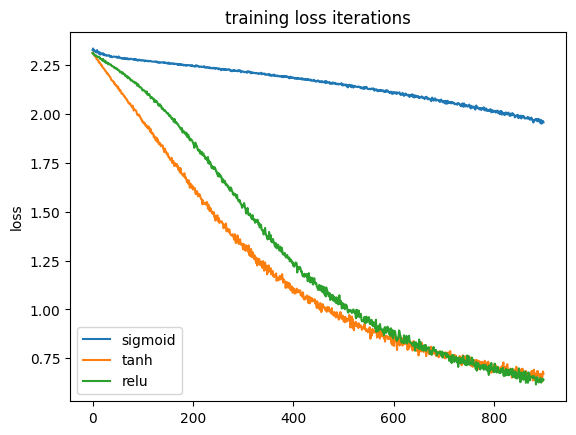

In [25]:
# Compare the training loss
plt.plot(train_sig['train_loss'], label='sigmoid')
plt.plot(train_tenh['train_loss'], label='tanh')
plt.plot(train_relu['train_loss'], label='relu')
plt.ylabel('loss')
plt.title('training loss iterations')
plt.legend()

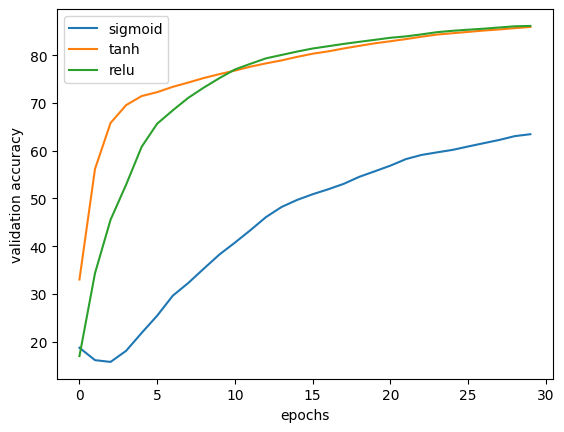

In [26]:
# Compare the validation accuracy
# Compare the training loss
plt.plot(train_sig['val_accu'], label='sigmoid')
plt.plot(train_tenh['val_accu'], label='tanh')
plt.plot(train_relu['val_accu'], label='relu')
plt.ylabel('validation accuracy')
plt.xlabel('epochs')
plt.legend()